In [1]:
!pip install -q --no-cache-dir --force-reinstall --no-deps git+https://github.com/RayenSansa03/aeroguard.git@main

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost
from tensorflow import keras

from aeroguard.autoencodeurs import erreur_reconstruction, standardiser
from aeroguard.decision import NIVEAUX, decider
from aeroguard.donnees_ml import preparer_xy
from aeroguard.hybride import centrer_par_moteur

DOSSIER = "/content/drive/MyDrive/aeroguard"

vols = pd.read_parquet(f"{DOSSIER}/data/processed/vols_ncmapss.parquet")
X_test, y_test = preparer_xy(vols, "test")
y_test = np.asarray(y_test)
infos = vols.loc[X_test.index, ["moteur", "cycle", "RUL", "famille"]].copy()
infos["famille"] = infos["famille"].astype(str)

# XGBoost v3 (champion de aeroguard-alerte)
xgb_v3 = xgboost.XGBClassifier()
xgb_v3.load_model(f"{DOSSIER}/models/xgb_binaire_v3.json")
xgb_v3.set_params(device="cpu")
probas_xgb = xgb_v3.predict_proba(X_test)[:, 1]

# Autoencodeur centré v5 (champion de aeroguard-anomalie)
stats = np.load(f"{DOSSIER}/models/autoencodeur_centre_v5_stats.npz", allow_pickle=True)
with open(f"{DOSSIER}/models/autoencodeur_centre_v5_alerte.json") as f:
    config_ae = json.load(f)
colonnes = [str(c) for c in stats["colonnes"]]
assert colonnes == list(X_test.columns), "Colonnes différentes de celles de la v5 !"

X_np = X_test.fillna(pd.Series(stats["medianes_imputation"], index=colonnes)).to_numpy(dtype="float64")
X_centre = centrer_par_moteur(X_np, infos["moteur"].to_numpy(), infos["cycle"].to_numpy(),
                              n_premiers=config_ae["n_premiers"])
Xn = standardiser(X_centre, stats["moyennes"], stats["ecarts"])
ae = keras.models.load_model(f"{DOSSIER}/models/autoencodeur_centre_v5.keras")
erreurs_feat = erreur_reconstruction(ae, Xn, par_feature=True)
erreurs_ae = erreurs_feat.mean(axis=1)

# Pendant les 10 premiers vols (ligne de base), l'autoencodeur ne peut pas encore juger
rang = infos.groupby("moteur")["cycle"].rank(method="first").to_numpy()
erreurs_ae = np.where(rang <= config_ae["n_premiers"], 0.0, erreurs_ae)

print(f"{len(X_test)} vols de test, {infos['moteur'].nunique()} moteurs | seuil AE {config_ae['seuil']:.3f}")

Mounted at /content/drive
2938 vols de test, 39 moteurs | seuil AE 0.618


In [3]:
def capteurs_en_cause(erreurs_vol, nombre=2):
    """Les capteurs dont les features sont le plus mal reconstruites sur ce vol."""
    ordre = np.argsort(erreurs_vol)[::-1]
    capteurs = []
    for j in ordre:
        capteur = colonnes[j].split("_")[0]
        if capteur not in capteurs:
            capteurs.append(capteur)
        if len(capteurs) == nombre:
            break
    return tuple(capteurs)


lignes = []
for moteur, groupe in infos.groupby("moteur"):
    positions = np.flatnonzero((infos["moteur"] == moteur).to_numpy())
    positions = positions[np.argsort(infos["cycle"].to_numpy()[positions])]
    for i in range(len(positions)):
        historique = positions[: i + 1]
        reco = decider(probas_xgb[historique], erreurs_ae[historique], seuil_ae=config_ae["seuil"],
                       k_ae=config_ae["k"], capteurs=capteurs_en_cause(erreurs_feat[positions[i]]))
        lignes.append({"moteur": moteur, "famille": groupe["famille"].iloc[0],
                       "cycle": int(infos["cycle"].iloc[positions[i]]), "RUL": int(infos["RUL"].iloc[positions[i]]),
                       "use": int(y_test[positions[i]]), **reco.en_dict()})

rejeu = pd.DataFrame(lignes)
rejeu.to_csv(f"{DOSSIER}/results/71_rejeu_decisions.csv", index=False)
print(f"{len(rejeu)} recommandations produites")
rejeu["niveau"].value_counts()

2938 recommandations produites


,count
niveau,
URGENT,1538
OK,1328
A_SURVEILLER,72


In [4]:
def premier(table, niveaux):
    sous_table = table[table["niveau"].isin(niveaux)]
    return sous_table["RUL"].iloc[0] if len(sous_table) else np.nan


bilan = (rejeu.groupby(["moteur", "famille"])
         .apply(lambda t: pd.Series({
             "RUL_1er_orange": premier(t, ["A_SURVEILLER", "URGENT"]),
             "RUL_1er_rouge": premier(t, ["URGENT"]),
             "niveau_final": t["niveau"].iloc[-1],
             "vols_sains_en_rouge": int(((t["niveau"] == "URGENT") & (t["use"] == 0)).sum()),
         }), include_groups=False)
         .reset_index())
bilan.to_csv(f"{DOSSIER}/results/71_bilan_flotte.csv", index=False)

print(f"Moteurs passés en orange ou rouge avant la panne : {bilan['RUL_1er_orange'].notna().sum()}/{len(bilan)}")
print(f"Moteurs passés en rouge avant la panne : {bilan['RUL_1er_rouge'].notna().sum()}/{len(bilan)}")
print(f"Avance médiane : orange {bilan['RUL_1er_orange'].median():.0f} vols | rouge {bilan['RUL_1er_rouge'].median():.0f} vols")
print(f"Vols SAINS classés URGENT (fausses urgences) : {int(bilan['vols_sains_en_rouge'].sum())}")
bilan.sort_values("RUL_1er_rouge").head(10)

Moteurs passés en orange ou rouge avant la panne : 39/39
Moteurs passés en rouge avant la panne : 39/39
Avance médiane : orange 40 vols | rouge 39 vols
Vols SAINS classés URGENT (fausses urgences) : 18


,moteur,famille,RUL_1er_orange,RUL_1er_rouge,niveau_final,vols_sains_en_rouge
34,DS08a_15,mixte,21,21,URGENT,0
35,DS08c_10,mixte,22,22,URGENT,0
31,DS08a_12,mixte,30,25,URGENT,0
38,DS08c_9,mixte,32,27,URGENT,0
27,DS07_8,LPT,28,28,URGENT,0
32,DS08a_13,mixte,31,31,URGENT,0
4,DS02_11,HPT+LPT,37,33,URGENT,0
30,DS08a_11,mixte,33,33,URGENT,0
20,DS05_9,HPC,35,35,URGENT,0
24,DS06_9,LPC+HPC,40,35,URGENT,0


In [5]:
moteur_exemple = bilan.sort_values("RUL_1er_rouge", ascending=False)["moteur"].iloc[0]
exemple = rejeu[(rejeu["moteur"] == moteur_exemple) & (rejeu["niveau"] != "OK")].iloc[[0, -1]]
for _, ligne in exemple.iterrows():
    print(json.dumps({k: ligne[k] for k in ["moteur", "cycle", "RUL", "niveau", "etat", "message", "capteurs"]},
                     ensure_ascii=False, indent=2, default=str))

{
  "moteur": "DS02_14",
  "cycle": 9,
  "RUL": 67,
  "niveau": "URGENT",
  "etat": "usure connue",
  "message": "Usure connue détectée (probabilité 96%).",
  "capteurs": []
}
{
  "moteur": "DS02_14",
  "cycle": 76,
  "RUL": 0,
  "niveau": "URGENT",
  "etat": "usure confirmée",
  "message": "Usure confirmée par les deux modèles : intervention prioritaire.",
  "capteurs": [
    "T48",
    "T50"
  ]
}


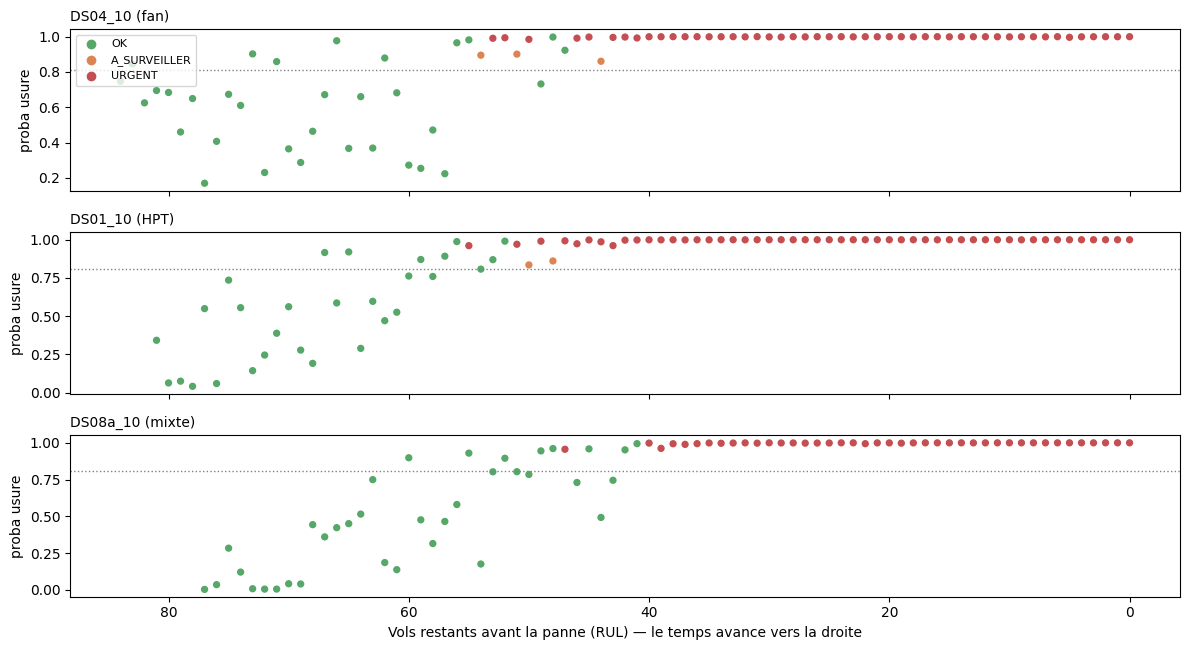

In [6]:
couleurs = {"OK": "#55A868", "A_SURVEILLER": "#DD8452", "URGENT": "#C44E52"}
exemples = [bilan[bilan["famille"] == f]["moteur"].iloc[0] for f in ["fan", "HPT", "mixte"]
            if (bilan["famille"] == f).any()]

fig, axes = plt.subplots(len(exemples), 1, figsize=(12, 2.2 * len(exemples)), sharex=True)
for axe, moteur in zip(np.atleast_1d(axes), exemples):
    t = rejeu[rejeu["moteur"] == moteur]
    axe.scatter(t["RUL"], t["proba_usure"], c=t["niveau"].map(couleurs), s=18)
    axe.axhline(0.81, color="gray", linestyle=":", linewidth=1)
    axe.set_ylabel("proba usure")
    axe.set_title(f"{moteur} ({t['famille'].iloc[0]})", fontsize=10, loc="left")
    axe.invert_xaxis()
np.atleast_1d(axes)[-1].set_xlabel("Vols restants avant la panne (RUL) — le temps avance vers la droite")
for niveau, couleur in couleurs.items():
    np.atleast_1d(axes)[0].scatter([], [], c=couleur, label=niveau)
np.atleast_1d(axes)[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/71_moteur_decision.png", dpi=150, bbox_inches="tight")
plt.show()